# Effective epsilon from independent implementations

Recomputes ε_eff from the saved TAPAS attack scores with `jax_privacy` and `privacy-estimates`
(`alt_eff_eps/estimate_eff_eps.py`); nothing here re-runs an attack or a generator. This notebook only
reads `results/alt_eff_eps.csv`.

Two things:
1. **Table** – worst-case attack per run, each implementation next to TAPAS.
2. **Plot** – ε_lower per implementation on every cell where TAPAS finds leakage.

Only 1000/2500 audits are shown (the CSV also has the smaller audit sizes). All numbers are the 95% confidence level at δ = 0, TAPAS's setting (it ignores δ). Formal δ for AIM and
DP-CTGAN changes the other methods by at most 2e-4 (first cell); joint-beta moves by up to 0.16, but only on near-zero cells, which is its numerical-integration tolerance rather than a δ effect (all its cells with ε > 0.3 are identical). `jax_gdp` is left out: the library takes
`abs(mu)` over thresholds, which inflates ε at near-trivial thresholds (AIM ε=10 ClosestDistance: 14, against 0 for every other method).

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

_cwd = Path.cwd()
HERE = next(c for c in (_cwd, _cwd / "alt_eff_eps") if (c / "results" / "alt_eff_eps.csv").exists())
FIG = HERE / "results" / "figures"; FIG.mkdir(exist_ok=True)

INK, MUTED, GRID = "#3A3A3A", "#6B6B6B", "#DDDDDD"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.facecolor": "white",
                     "font.size": 10, "hatch.linewidth": .8})

df = pd.read_csv(HERE / "results" / "alt_eff_eps.csv")
df = df[df.method != "jax_raw_counts"]
# 1000/2500 audits only, and not the sample-size-sweep DPGAN stages (seed_fix=False duplicates of the eps sweep)
df = df[(df.num_train == 1000) & (df.num_test == 2500) & ~df.run.str.startswith("sample_size_sweep/dpgan/")]
P = df[(df.confidence == 0.95) & df.delta_label.str.startswith("0")].copy()    # delta = 0, 95%

# ---- checks ----
rep = df[df.method == "tapas_replica"]
print(f"{len(df):,} rows | {df.run.nunique()} runs | replica vs saved TAPAS eps_low: "
      f"max |diff| = {(rep.eps_lower - rep.tapas_eps_lower).abs().max():.1e}")
f = df[(df.delta_label == "formal") & (df.method != "jax_gdp")]
z = df[df.delta_label.str.startswith("0")].merge(f, on=["run", "attack", "confidence", "method"], suffixes=("", "_f"))
z["d"] = (z.eps_lower - z.eps_lower_f).abs()
print("formal delta vs delta=0, max |diff| by method:", z.groupby("method").d.max().round(4).to_dict())

GEN = {"bayesian_network": "BN", "ctgan": "CTGAN", "aim": "AIM", "dp_ctgan": "DP-CTGAN", "dpgan": "DPGAN"}
TAG = {"seedfix": "seed fix", "seedbase10000": "seed base 10000", "tseed44": "target seed 44", "bg44": "background seed 44"}
def nice(run):
    """Readable run label. 1000/2500 is the default size and is left out; ss/ runs are at eps = 1."""
    size = lambda z: "" if z == "1000_2500" else ", " + z.replace("_", "/")
    if m := re.fullmatch(r"sample_size_sweep/dpgan/(\d+_\d+)", run):
        return f"DPGAN (ε = 1, sweep {m[1].replace('_', '/')})"
    if m := re.fullmatch(r"sample_size_sweep/(\w+)/(\d+_\d+)", run):
        g, z = m.groups()
        return GEN[g] + (f" (ε = 1{size(z)})" if g in ("aim", "dp_ctgan") else (f" ({z.replace('_', '/')})" if z != "1000_2500" else ""))
    if m := re.fullmatch(r"eps_sweep/(aim|dp_ctgan)/eps([\d.]+)/1000_2500", run):
        return f"{GEN[m[1]]} (ε = {m[2]})"
    if m := re.fullmatch(r"eps_sweep/dpgan/eps([\d.]+?)(?:_(\w+))?", run):
        return f"DPGAN (ε = {m[1]}" + (f", {TAG[m[2]]}" if m[2] else "") + ")"
    return run

def sort_key(run):
    """generator, then formal eps, then audit size (default 1000/2500), then label"""
    lab = nice(run)
    eps = re.search(r"ε = ([\d.]+)", lab); sz = re.search(r"(\d+)/\d+", lab)
    return (list(GEN.values()).index(lab.split(" (")[0]), float(eps[1]) if eps else 0.0,
            int(sz[1]) if sz else 1000, lab)

METHODS = [  # column, label, colour, marker  (non-generator figure: reference-chart palette, not Okabe-Ito)
    ("tapas_replica",            "TAPAS",                        INK,       "o"),
    ("pe_clopper_pearson",       "priv-est Clopper-Pearson",     "#CE4E36", "s"),
    ("pe_jeffreys",              "priv-est Jeffreys",            "#E8A090", "s"),
    ("pe_joint_beta",            "priv-est joint-beta",          "#8E2F1C", "D"),
    ("jax_cp_split",             "jax Split",                    "#8CA9A0", "^"),
    ("jax_cp_split_tapas_tails", "jax Split (TAPAS tails)",      "#4F7A6E", "^"),
    ("jax_cp_multisplit",        "jax MultiSplit",               "#B8CCC6", "v"),
    ("jax_cp_bonferroni",        "jax Bonferroni",               "#2F4F46", "v"),
]
LABEL = {m: l for m, l, _, _ in METHODS}
W = P.pivot_table(index=["tier", "run", "attack"], columns="method", values="eps_lower", sort=False)
W["TAPAS_ref"] = P[P.method == "tapas_replica"].set_index(["tier", "run", "attack"]).tapas_eps_lower
print(f"cells with TAPAS > 0: {(W.TAPAS_ref > 0).sum()} of {len(W)}")
null = W[W.TAPAS_ref == 0]
print(f"on the {len(null)} cells where TAPAS = 0, share with eps > 0.05:")
print((null[[m for m, *_ in METHODS]] > .05).mean().round(2).rename(LABEL).to_string())

3,900 rows | 26 runs | replica vs saved TAPAS eps_low: max |diff| = 1.3e-11
formal delta vs delta=0, max |diff| by method: {'jax_cp_bonferroni': 0.0002, 'jax_cp_multisplit': 0.0, 'jax_cp_split': 0.0, 'jax_cp_split_tapas_tails': 0.0, 'pe_clopper_pearson': 0.0, 'pe_jeffreys': 0.0, 'pe_joint_beta': 0.1587}
cells with TAPAS > 0: 14 of 130
on the 116 cells where TAPAS = 0, share with eps > 0.05:
method
TAPAS                       0.00
priv-est Clopper-Pearson    0.00
priv-est Jeffreys           0.00
priv-est joint-beta         0.22
jax Split                   0.02
jax Split (TAPAS tails)     0.02
jax MultiSplit              0.02
jax Bonferroni              0.03


## Table – worst-case attack per run

The paper's convention: for each implementation, the largest ε_lower over the five attacks. Tier 1 runs are the
headline (1000/2500, `seed_fix` DPGAN arms); `seed_fix=False` DPGAN arms are tier "secondary" and their
confidence intervals are not independent (fits share training noise).

**Shading** marks where ε_eff exceeds the run's formal ε, darker the further over (one scale for both
tables). A non-zero ε_eff below the formal budget is left unshaded, because it is consistent with the guarantee.
BN and CTGAN have no formal ε (–), so they are never shaded.

In [2]:
T = (P.groupby(["tier", "run", "method"]).eps_lower.max().unstack("method")
       .reindex(columns=[m for m, *_ in METHODS]))
T.columns = [LABEL[c] for c in T.columns]
T = T.reset_index()
order = {"1": 0, "2": 1, "secondary": 2}
T["_t"], T["_k"] = T.tier.map(order), T.run.map(sort_key)
T = T.sort_values(["_t", "_k"]).drop(columns=["_t", "_k"])
T.insert(2, "formal ε", T.run.map(P.groupby("run").formal_epsilon.first()))   # NaN = non-DP
T["run"] = T.run.map(nice)

# Shade only where eps_eff EXCEEDS the formal budget, darker the further over. One scale for both tables.
COLS = [LABEL[m] for m, *_ in METHODS]
EXCESS = T[COLS].sub(T["formal ε"], axis=0).clip(lower=0)      # NaN for non-DP rows -> unshaded
VMAX = float(EXCESS.max().max())
CMAP = plt.get_cmap("Oranges")

def shade(block):
    def css(v):
        if not v > 0:
            return ""
        r = .2 + .8 * min(v / VMAX, 1)          # floor at .2 so a small exceedance is still visible
        return f"background-color: {mcolors.to_hex(CMAP(r))}; color: {'white' if r > .6 else 'black'}"
    out = pd.DataFrame("", index=block.index, columns=block.columns)
    out[COLS] = block[COLS].sub(block["formal ε"], axis=0).clip(lower=0).map(css)
    return out

print(f"shading: eps_lower - formal eps, 0 (unshaded) to {VMAX:.2f} (darkest)")
for t, title in [("1", "Tier 1 - headline"), ("secondary", "Secondary - seed_fix=False DPGAN (CI independence violated)")]:
    print(f"\n{title}")
    tbl = T[T.tier == t].drop(columns="tier").set_index("run")
    display(tbl.style.format("{:.3f}", subset=COLS).format("{:g}", subset=["formal ε"], na_rep="–")
            .apply(shade, axis=None))

shading: eps_lower - formal eps, 0 (unshaded) to 3.97 (darkest)

Tier 1 - headline


,formal ε,TAPAS,priv-est Clopper-Pearson,priv-est Jeffreys,priv-est joint-beta,jax Split,jax Split (TAPAS tails),jax MultiSplit,jax Bonferroni
run,,,,,,,,,
BN,–,0.000,0.000,0.000,0.516,0.000,0.000,0.000,0.026
CTGAN,–,0.846,0.846,0.853,0.973,0.746,0.721,0.837,0.922
AIM (ε = 0.1),0.1,0.000,0.000,0.000,0.706,0.000,0.000,0.000,0.000
AIM (ε = 1),1,0.000,0.000,0.000,0.079,0.000,0.000,0.000,0.000
AIM (ε = 10),10,0.368,0.368,0.370,0.516,0.368,0.349,0.385,0.457
DP-CTGAN (ε = 0.1),0.1,0.000,0.000,0.000,0.079,0.000,0.000,0.000,0.000
DP-CTGAN (ε = 1),1,0.000,0.000,0.000,0.079,0.000,0.000,0.000,0.000
DP-CTGAN (ε = 10),10,0.000,0.000,0.000,0.039,0.000,0.000,0.000,0.000
DP-CTGAN (ε = 100),100,0.000,0.000,0.000,0.035,0.000,0.000,0.000,0.000



Secondary - seed_fix=False DPGAN (CI independence violated)


,formal ε,TAPAS,priv-est Clopper-Pearson,priv-est Jeffreys,priv-est joint-beta,jax Split,jax Split (TAPAS tails),jax MultiSplit,jax Bonferroni
run,,,,,,,,,
DPGAN (ε = 0.1),0.1,0.000,0.000,0.000,0.118,0.000,0.000,0.000,0.077
DPGAN (ε = 0.5),0.5,4.195,4.195,4.281,4.474,3.880,3.812,3.928,4.326
DPGAN (ε = 1),1,1.617,1.617,1.624,1.723,1.791,1.742,1.968,2.133
"DPGAN (ε = 1, background seed 44)",1,2.773,2.773,2.786,2.871,2.713,2.668,3.390,3.778
"DPGAN (ε = 1, seed base 10000)",1,2.592,2.592,2.619,2.771,1.774,1.736,2.577,2.548
"DPGAN (ε = 1, target seed 44)",1,2.892,2.892,2.912,3.021,2.975,2.922,3.139,3.740
DPGAN (ε = 2),2,1.578,1.578,1.605,1.868,1.214,1.177,1.455,1.540
DPGAN (ε = 5),5,0.108,0.108,0.110,0.173,0.000,0.000,0.000,0.100
DPGAN (ε = 10),10,0.000,0.000,0.000,0.194,0.000,0.000,0.000,0.000


## Plot – ε_lower per implementation, cells where TAPAS finds leakage

One row per (run, attack) with TAPAS ε_lower > 0 (95%, δ = 0). Rows are grouped Tier 1 on top, then the
`seed_fix=False` DPGAN arms (shaded). Within a row each implementation sits at its own height so overlapping
values stay visible; the grey bar is TAPAS's own 95% interval. Cells where TAPAS = 0 are not drawn: on those,
every Clopper-Pearson-type method stays near 0, and the printout in the first cell lists how often each method
reports ε > 0.05 there.

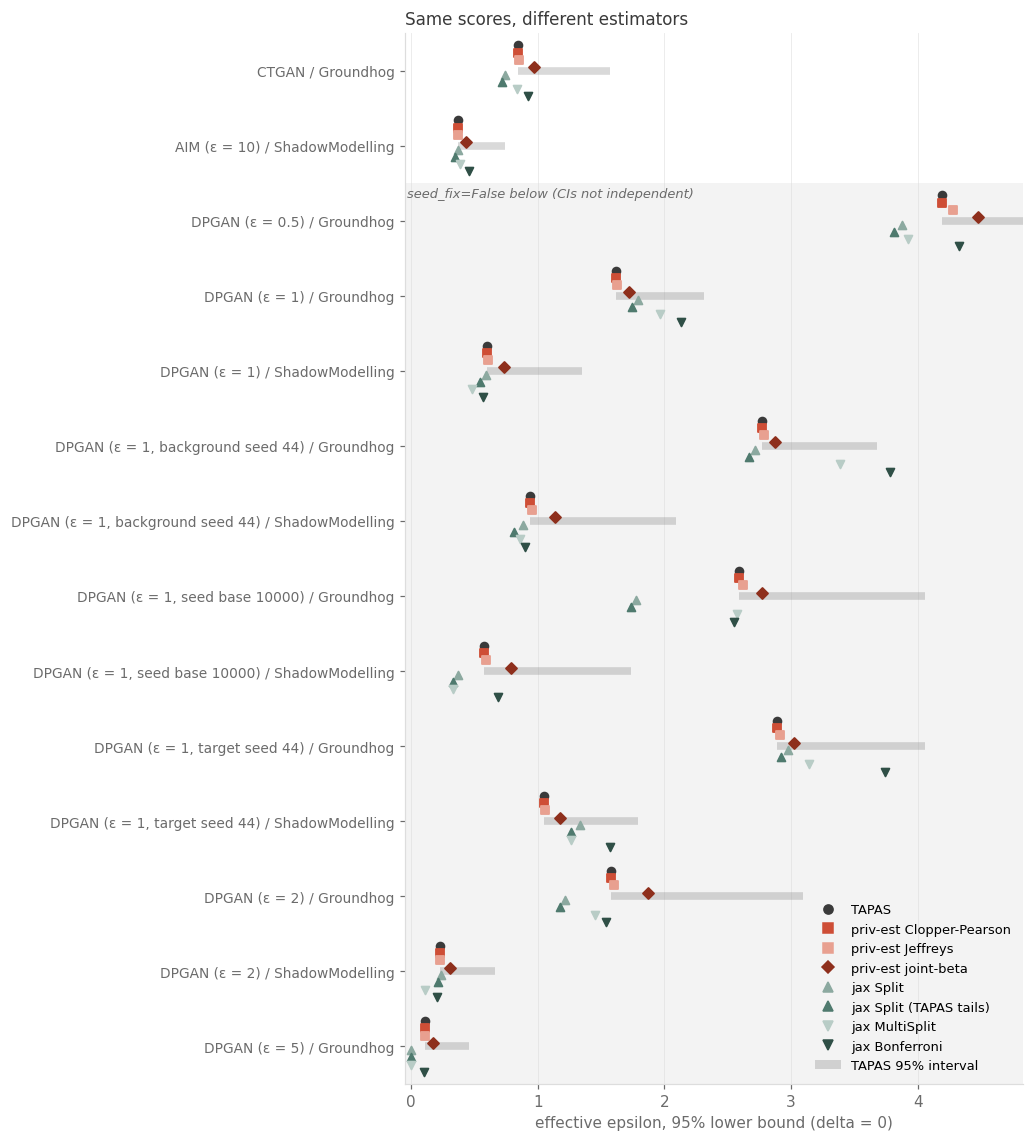

In [3]:
S = W[W.TAPAS_ref > 0].reset_index()
S["g"] = S.tier.map({"1": 0, "2": 1, "secondary": 2})
S["_k"] = S.run.map(sort_key)
S = S.sort_values(["g", "_k", "attack"]).reset_index(drop=True)
up = P[P.method == "tapas_replica"].set_index(["run", "attack"]).tapas_eps_upper

n = len(S); k = len(METHODS)
offs = np.linspace(-.34, .34, k)
fig, ax = plt.subplots(figsize=(9.5, .62 * n + 1.8))
xmax = float(S[[m for m, *_ in METHODS]].max().max()) * 1.08
for i, r in S.iterrows():
    if r.g == 2:
        ax.axhspan(i - .5, i + .5, facecolor=GRID, alpha=.35, edgecolor="none", zorder=0)
    hi = up.loc[(r.run, r.attack)]
    ax.plot([r.TAPAS_ref, min(hi, xmax)], [i, i], color=MUTED, lw=5, alpha=.25, solid_capstyle="butt", zorder=1)
for j, (m, lab, col, mk) in enumerate(METHODS):
    ax.scatter(S[m], np.arange(n) + offs[j], s=26, marker=mk, color=col, zorder=3,
               linewidths=1.2, label=lab)
ax.set_yticks(range(n)); ax.set_yticklabels([f"{nice(r.run)} / {r.attack}" for r in S.itertuples()], fontsize=9)
ax.invert_yaxis(); ax.set_ylim(n - .5, -.5); ax.set_xlim(-.05, xmax)
ax.set_xlabel("effective epsilon, 95% lower bound (delta = 0)", color=MUTED)
ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color(GRID)
ax.tick_params(colors=MUTED, length=3); ax.grid(axis="x", color=GRID, lw=.6, alpha=.6); ax.set_axisbelow(True)
if (S.g == 0).any() and (S.g == 2).any():
    ax.text(-.03, (S.g == 0).sum() - .5 + .05, "seed_fix=False below (CIs not independent)", ha="left", va="top",
            fontsize=8.5, color=MUTED, style="italic")
handles = [Line2D([], [], marker=mk, ls="", color=col, markersize=6, label=lab) for _, lab, col, mk in METHODS]
handles.append(plt.Rectangle((0, 0), 1, 1, facecolor=MUTED, alpha=.25, label="TAPAS 95% interval"))
ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=8.5)
ax.set_title("Same scores, different estimators", loc="left", color=INK, fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "eps_by_implementation.png"); plt.show()